# CustomerIQ — AI-Powered Customer Intelligence & Retention
**Predict → Segment → Explain → Recommend**

This notebook walks through the full ML workflow: data → preprocessing → EDA → feature engineering → supervised learning → unsupervised learning → evaluation → explainable AI → recommendations.

In [1]:
import sys; sys.path.insert(0, '../src')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from customeriq import churn, segmentation, explain
from customeriq.data import load_or_generate
from customeriq.features import add_features, TARGET
from customeriq.config import RANDOM_STATE
sns.set_theme(style='whitegrid')

## 1. Customer data

In [2]:
df = load_or_generate()
print(df.shape, f'| churn rate {df.churn.mean():.1%}')
df.head()

(25430, 15) | churn rate 14.7%


,customer_id,age,region,tenure_months,contract_type,payment_method,monthly_spend,total_spend,num_orders,logins_per_month,avg_session_minutes,days_since_last_purchase,support_tickets,discount_usage_rate,churn
0,CUST-10000,27,Central,6,One year,Net Banking,55.56,325.69,1,4,5.7,65,0,0.052,0
1,CUST-10001,46,West,16,One year,Credit Card,113.32,1557.03,18,7,19.6,41,0,0.582,0
2,CUST-10002,71,North,10,Month-to-month,UPI,54.81,509.49,6,4,9.4,110,2,0.409,0
3,CUST-10003,48,North,3,Two year,UPI,46.96,123.08,2,2,8.1,38,2,0.509,0
4,CUST-10004,43,East,56,One year,Credit Card,151.26,7240.71,142,23,20.5,12,1,0.236,0


In [3]:
df.isna().mean().loc[lambda s: s > 0].to_frame('missing share')

,missing share
avg_session_minutes,0.016555
discount_usage_rate,0.015218


## 2. Exploratory data analysis

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
df.churn.map({0: 'Stayed', 1: 'Churned'}).value_counts().plot.bar(ax=ax[0,0], title='Churn distribution', rot=0)
for a, c in zip(ax.flat[1:], ['tenure_months', 'logins_per_month', 'days_since_last_purchase', 'support_tickets', 'monthly_spend']):
    sns.kdeplot(data=df, x=c, hue='churn', common_norm=False, fill=True, ax=a); a.set_title(c)
plt.tight_layout()

In [5]:
d = df.assign(age_band=pd.cut(df.age, [17,25,35,45,55,65,100]), tenure_band=pd.cut(df.tenure_months, [0,6,12,24,48,100]))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
d.groupby('age_band', observed=True).churn.mean().plot.bar(ax=ax[0], title='Churn rate by age'); d.groupby('tenure_band', observed=True).churn.mean().plot.bar(ax=ax[1], title='Churn rate by tenure')
plt.tight_layout()

In [6]:
plt.figure(figsize=(9, 6)); sns.heatmap(df.select_dtypes('number').corr(), cmap='coolwarm', center=0, annot=False); plt.title('Correlation matrix')

Text(0.5, 1.0, 'Correlation matrix')

## 3. Feature engineering
We add `orders_per_month`, `avg_order_value`, `tickets_per_month` and `engagement_score`.

In [7]:
feat = add_features(df)
feat[['orders_per_month','avg_order_value','tickets_per_month','engagement_score']].describe().round(2)

,orders_per_month,avg_order_value,tickets_per_month,engagement_score
count,25430.00,25430.00,25430.00,25009.00
mean,1.22,79.79,0.24,0.90
std,0.60,55.77,0.26,0.52
min,0.06,13.90,0.00,0.03
25%,0.77,48.98,0.00,0.47
50%,1.12,65.93,0.17,0.82
75%,1.58,91.31,0.33,1.17
max,4.03,1349.00,5.00,3.04


## 4. Supervised learning — churn prediction
Stratified 80/20 split; class imbalance handled with `class_weight='balanced'`. We compare on ROC-AUC / PR-AUC (accuracy alone is misleading at ~15% churn).

In [8]:
X, y = feat[churn.FEATURES], feat[TARGET]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
results, fitted = churn.evaluate_models(X_tr, y_tr, X_te, y_te)
results.round(4)

  Logistic Regression  ROC-AUC=0.8727  F1=0.5212


  Decision Tree        ROC-AUC=0.8530  F1=0.4920


  Random Forest        ROC-AUC=0.8656  F1=0.5570


  KNN                  ROC-AUC=0.8479  F1=0.4476


  SVM                  ROC-AUC=0.8461  F1=0.5133


  XGBoost              ROC-AUC=0.8677  F1=0.4975


,model,roc_auc,pr_auc,accuracy,precision,recall,f1
0,Logistic Regression,0.8727,0.6075,0.7847,0.3875,0.7957,0.5212
1,XGBoost,0.8677,0.5995,0.8797,0.6461,0.4045,0.4975
2,Random Forest,0.8656,0.5827,0.8427,0.4759,0.6716,0.5570
3,Decision Tree,0.8530,0.5316,0.7633,0.3597,0.7784,0.4920
4,KNN,0.8479,0.5450,0.8757,0.6481,0.3418,0.4476
5,SVM,0.8461,0.4781,0.7833,0.3835,0.7757,0.5133


In [9]:
from sklearn.metrics import roc_curve, roc_auc_score
plt.figure(figsize=(6.5, 5))
for n, p in fitted.items():
    s = p.predict_proba(X_te)[:, 1] if hasattr(p, 'predict_proba') else p.decision_function(X_te)
    f, t, _ = roc_curve(y_te, s); plt.plot(f, t, label=f'{n} ({roc_auc_score(y_te, s):.3f})')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.title('ROC curves'); plt.xlabel('FPR'); plt.ylabel('TPR')

Text(0, 0.5, 'TPR')

### Calibration → probability + risk level
Raw probabilities from class-weighted models are inflated, so the deployed model is wrapped in `CalibratedClassifierCV`. Risk bands: **<30% Low · 30–60% Medium · ≥60% High**.

In [10]:
best = results.loc[0, 'model']; print('Best model:', best)
final = churn.fit_calibrated(best, X_tr, y_tr)
proba = final.predict_proba(X_te)[:, 1]
print(f'mean predicted prob {proba.mean():.3f} vs actual churn {y_te.mean():.3f}')
from sklearn.calibration import calibration_curve
fp, mp = calibration_curve(y_te, proba, n_bins=10, strategy='quantile')
plt.plot(mp, fp, 'o-'); plt.plot([0,1],[0,1],'k--'); plt.xlabel('Predicted'); plt.ylabel('Observed'); plt.title('Calibration')

Best model: Logistic Regression


mean predicted prob 0.152 vs actual churn 0.147


Text(0.5, 1.0, 'Calibration')

## 5. Explainable AI (SHAP)

In [11]:
exp = explain.build_explainer(fitted['XGBoost'], feat.loc[X_tr.index])
sample = feat.sample(3000, random_state=1)
Xs, sv = explain.shap_values(exp, sample)
import shap
shap.summary_plot(sv, Xs, feature_names=exp['names'], max_display=12)

In [12]:
imp = explain.global_importance(exp, sv); imp.head(10)

,feature,mean_abs_shap
0,days_since_last_purchase,0.795606
1,contract_type,0.543754
2,engagement_score,0.373879
3,discount_usage_rate,0.320556
4,tickets_per_month,0.271916
5,num_orders,0.213599
6,tenure_months,0.156999
7,support_tickets,0.149654
8,logins_per_month,0.117849
9,total_spend,0.083437


## 6. Unsupervised learning — customer segmentation
First choose *k* with the elbow method and silhouette score, then fit K-Means, cross-check with hierarchical clustering, and project to 2D with PCA.

In [13]:
proba_all = final.predict_proba(X)[:, 1]
seg_art, diag = segmentation.fit_segmentation(feat, proba_all)
diag['k_selection'].round(3)

,k,inertia,silhouette
0,2,108587.315,0.324
1,3,85345.137,0.284
2,4,75711.058,0.251
3,5,69407.596,0.216
4,6,63887.198,0.228
5,7,60661.399,0.215
6,8,58068.667,0.214


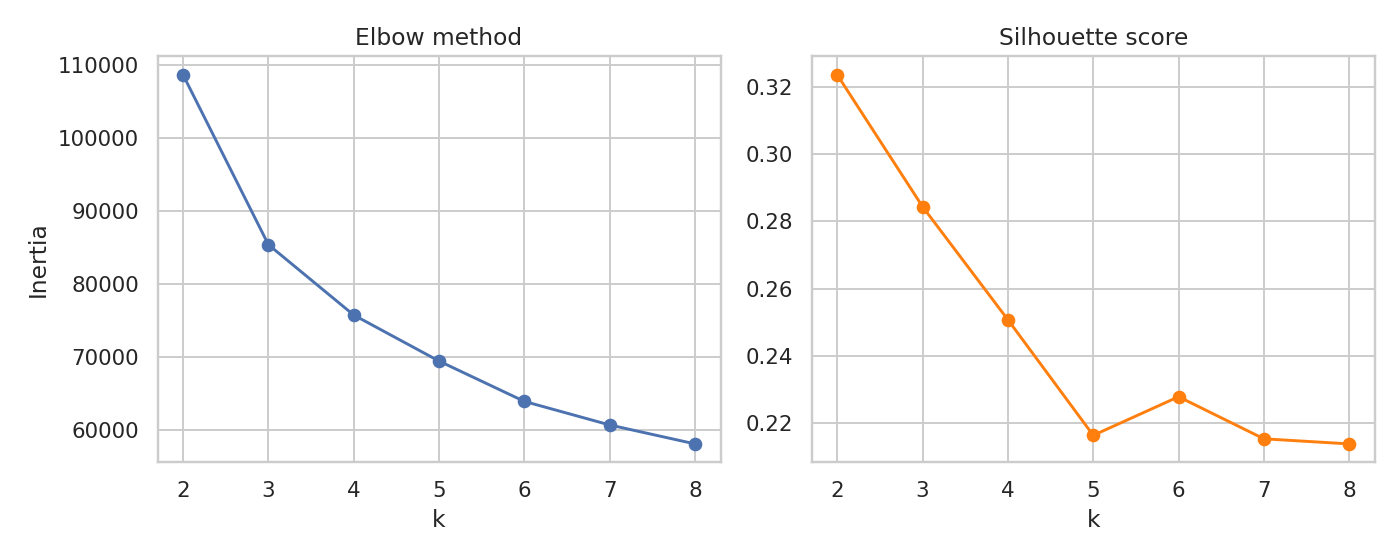

In [14]:
segmentation.plot_k_selection(diag['k_selection'], path='/tmp/k.png')
from IPython.display import Image; Image('/tmp/k.png')

silhouette(k=4) = 0.251 | hierarchical vs K-Means ARI = 0.730 | PCA variance = [0.568 0.138]


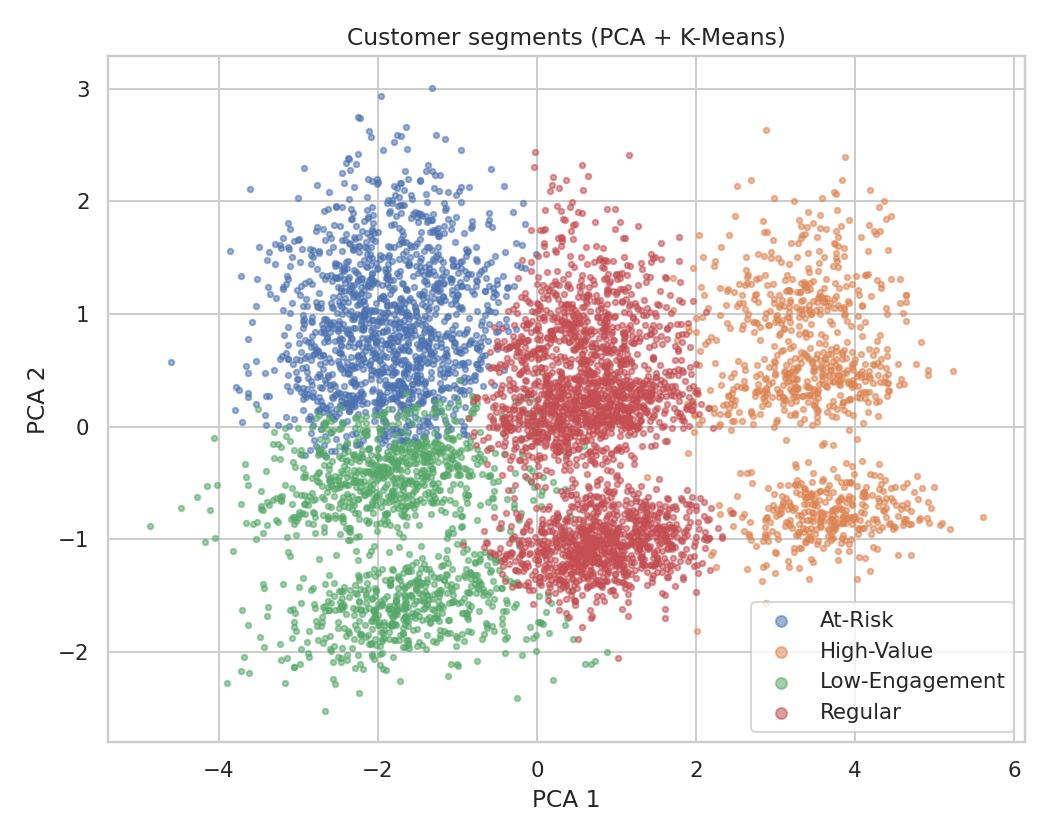

In [15]:
print(f"silhouette(k=4) = {diag['silhouette_k']:.3f} | hierarchical vs K-Means ARI = {diag['hierarchical_vs_kmeans_ARI']:.3f} | PCA variance = {np.round(diag['pca_explained_variance'], 3)}")
seg = segmentation.assign_segments(seg_art, feat)
segmentation.plot_clusters(seg, path='/tmp/c.png'); Image('/tmp/c.png')

In [16]:
prof = feat.join(seg).assign(churn_prob=proba_all).groupby('segment')[['monthly_spend','logins_per_month','days_since_last_purchase','support_tickets','churn_prob']].mean().round(2)
prof.assign(customers=seg.segment.value_counts())

,monthly_spend,logins_per_month,days_since_last_purchase,support_tickets,churn_prob,customers
segment,,,,,,
At-Risk,59.76,5.78,86.19,3.06,0.39,5913
High-Value,184.08,21.76,11.90,1.02,0.01,3993
Low-Engagement,67.75,3.90,60.28,0.69,0.17,5523
Regular,80.52,11.92,30.76,0.97,0.05,10001


## 7. Predict → Segment → Explain → Recommend
(Uses the trained artifacts in `../models/` — run `python run_pipeline.py` once first.)

In [17]:
from customeriq.inference import CustomerIQ
engine = CustomerIQ()
out = engine.score(df.sample(2000, random_state=3))
out.risk_level.value_counts()

risk_level
Low       1654
Medium     238
High       108
Name: count, dtype: int64

In [18]:
row = out.sort_values('churn_probability', ascending=False).iloc[0]
print(f"Customer: {row.customer_id}\nRisk: {row.risk_level}\nChurn Probability: {row.churn_probability:.1%}\nSegment: {row.segment_label}\n\nTop churn factors:")
for f in row.top_factors.split(' | '): print('  •', f)
print('\nRecommended Action:')
for a in row.recommended_actions.split(' | '): print('  →', a)

Customer: CUST-27954
Risk: High
Churn Probability: 98.9%
Segment: At-Risk

Top churn factors:
  • Long time since last purchase
  • Contract Type: Month-to-month
  • Low engagement

Recommended Action:
  → Contact customer
  → Offer retention campaign
  → Send win-back offer
  → Offer contract-upgrade / loyalty incentive
  → Increase product engagement


## Next steps
- `python run_pipeline.py` — train and score everything
- `uvicorn api.main:app --reload` — REST API
- `streamlit run app/dashboard.py` — interactive dashboard